# Pandas: map, apply und der Erwartungswert
### Unterrichtsmaterial | Julia Brutskaya | FIDP / Daten- und Prozessanalyse

---
**Kontext:** Wahrscheinlichkeitsrechnung, Tag 3 – Datenwald-Akademie und Fietes Tombola<br>
**Bibliotheken:** `pandas`, `numpy`, `matplotlib`, `itertools`, `math`

<img src="png%20Dateien/fiete_fuchs.png" alt="Fiete Fuchs" width="150"> <img src="png%20Dateien/etta_elster.png" alt="Etta" width="130"> <img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="130">

Heute Vormittag ging es ums Zählen, um Zufallsvariablen, den Erwartungswert und die Binomialverteilung. Fiete Fuchs hat eine Tombola eröffnet, und Herr Bauchgefühl hat wieder ein paar Rechnungen aufgestellt.

Heute Nachmittag lernst du zwei der wichtigsten Pandas-Werkzeuge überhaupt: **`map`** und **`apply`**. Mit ihnen übersetzt du Werte in andere Werte, und genau das ist eine Zufallsvariable.

| Block | Inhalt | Neu in Pandas |
|---|---|---|
| A | Zählen mit Tabellen | `itertools` → DataFrame, der `int64`-Überlauf |
| B | Die Zufallsvariable ist ein `map` | `map` mit Dict und Funktion, `replace` |
| C | Verteilung und Erwartungswert | `(x * p).sum()`, `np.average(weights=…)`, `cumsum`, `pd.Series(dict)` |
| D | Fietes Tombola simulieren | `sample` + `map` + `expanding` |
| E | Die Binomialverteilung als Tabelle | `apply` auf eine Series, `rng.binomial`, `mul(…, axis=0)` |
| F | `apply` zeilenweise, Gleichverteilung und weitere Übungen | `apply(…, axis=1)`, `rng.integers` |

---
# Block A – Zählen mit Tabellen

## 1 – Alle Möglichkeiten als DataFrame

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="120">

> **Herr Bauchgefühl:** „Mein Server-Passwort hat vier Ziffern. Das errät doch keiner, das sind ja unzählig viele Möglichkeiten."

Das Modul `itertools` aus der Python-Standardbibliothek erzeugt alle Möglichkeiten. `pd.DataFrame(list(...))` macht daraus eine Tabelle. Die Zeilenzahl prüft die Formel vom Vormittag.

| `itertools` | Grundfall | Formel |
|---|---|---|
| `product(..., repeat=k)` | Reihenfolge wichtig, mit Zurücklegen | nᵏ |
| `permutations(..., k)` | Reihenfolge wichtig, ohne Zurücklegen | n! / (n − k)! |
| `combinations(..., k)` | Reihenfolge egal, ohne Zurücklegen | (n über k) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product, permutations, combinations
from math import comb, factorial

pins = pd.DataFrame(list(product(range(10), repeat=4)), columns=["z1", "z2", "z3", "z4"])
print("PINs:", len(pins))
pins.sample(5, random_state=1)

PINs: 10000


,z1,z2,z3,z4
9953,9,9,5,3
3850,3,8,5,0
4962,4,9,6,2
3886,3,8,8,6
5437,5,4,3,7


In [2]:
print("Platz 1-3 aus 20, Reihenfolge wichtig:", len(list(permutations(range(1, 21), 3))), "=", 20 * 19 * 18)
print("3 aus 20, Reihenfolge egal:           ", len(list(combinations(range(1, 21), 3))), "=", comb(20, 3))

kurs = [f"P{i}" for i in range(1, 9)]
paare = pd.DataFrame(list(combinations(kurs, 2)), columns=["person1", "person2"])
print("Präsentationspaare aus 8 Personen:    ", len(paare), "=", comb(8, 2))
paare.head()

Platz 1-3 aus 20, Reihenfolge wichtig: 6840 = 6840
3 aus 20, Reihenfolge egal:            1140 = 1140
Präsentationspaare aus 8 Personen:     28 = 28


,person1,person2
0,P1,P2
1,P1,P3
2,P1,P4
3,P1,P5
4,P1,P6


## 2 – Die Münzwurf-Pfade

Im Skript stehen die 6 Pfade, auf denen bei 4 Würfen genau 2-mal Kopf fällt. `product("KZ", repeat=4)` erzeugt alle 16 Pfade. Mit `sum(axis=1)` zählst du die Köpfe pro Zeile (kennst du aus Notebook 8).

In [3]:
pfade = pd.DataFrame(list(product("KZ", repeat=4)), columns=["w1", "w2", "w3", "w4"])
pfade["kopf"] = (pfade[["w1", "w2", "w3", "w4"]] == "K").sum(axis=1)

print("alle Pfade:", len(pfade), "| davon genau 2-mal Kopf:", (pfade["kopf"] == 2).sum(), "=", comb(4, 2))
print()

# die 6 Pfade als Text: apply mit "".join klebt die vier Buchstaben einer Zeile zusammen
zwei_kopf = pfade.loc[pfade["kopf"] == 2, ["w1", "w2", "w3", "w4"]]
print(zwei_kopf.apply("".join, axis=1).tolist())
print()
print("Anzahl Pfade je Kopfzahl:", pfade["kopf"].value_counts().sort_index().tolist())

alle Pfade: 16 | davon genau 2-mal Kopf: 6 = 6

['KKZZ', 'KZKZ', 'KZZK', 'ZKKZ', 'ZKZK', 'ZZKK']

Anzahl Pfade je Kopfzahl: [1, 4, 6, 4, 1]


1, 4, 6, 4, 1 ist Zeile 4 im Pascalschen Dreieck.

> **Stolperstein:** `"".join` klebt nur Text zusammen. Wähle deshalb vorher die vier Buchstaben-Spalten aus. Ist die Zahlenspalte `kopf` dabei, bricht `apply` mit einem `TypeError` ab.

## 3 – Wenn die Zahl zu groß wird: der `int64`-Überlauf

Wir bauen die Passwort-Tabelle aus dem Skript nach.

In [4]:
vergleich = pd.DataFrame({"n": [4, 6, 8, 12], "zeichen": [10, 26, 62, 62]})
vergleich["moeglichkeiten"] = vergleich["zeichen"] ** vergleich["n"]
vergleich

,n,zeichen,moeglichkeiten
0,4,10,10000
1,6,26,308915776
2,8,62,218340105584896
3,12,62,-1913450501271711744


<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="120">

Ein **negatives** Ergebnis bei 12 Zeichen! Pandas speichert ganze Zahlen als `int64`, das reicht nur bis etwa 9,2 · 10¹⁸. 62¹² ≈ 3,2 · 10²¹ passt nicht hinein und „läuft über", **ohne Fehlermeldung**.

> **Achtung:** Bei großen Potenzen vorher in Kommazahlen umwandeln (`astype(float)`). Reines Python rechnet dagegen richtig, weil Python-Ganzzahlen beliebig groß sein dürfen.

In [5]:
print("reines Python:", 62 ** 12)
print("int64-Grenze: ", np.iinfo(np.int64).max)
print()

vergleich["moeglichkeiten"] = vergleich["zeichen"].astype(float) ** vergleich["n"]
vergleich["tage"] = vergleich["moeglichkeiten"] / 1e9 / 86400     # 10⁹ Versuche pro Sekunde
vergleich.round(2)

reines Python: 3226266762397899821056
int64-Grenze:  9223372036854775807



,n,zeichen,moeglichkeiten,tage
0,4,10,1.000000e+04,0.00
1,6,26,3.089158e+08,0.00
2,8,62,2.183401e+14,2.53
3,12,62,3.226267e+21,37341050.49


Bei einer Milliarde Versuche pro Sekunde: 8 Zeichen sind in 2,5 Tagen geknackt, 12 Zeichen brauchen über 37 Millionen Tage.

### Übung 1

Übung 1 vom Vormittag. Ein Programm probiert 10⁹ Passwörter pro Sekunde.

- **a)** Erzeuge alle PINs mit 4 Ziffern mit `product`. Wie viele sind es, und wie lange dauert das Ausprobieren?
- **b)** Wie viele Passwörter aus 6 Kleinbuchstaben gibt es? Wie lange dauert es? *Hinweis: Hier nicht alle erzeugen, nur rechnen.*
- **c)** Wie viele Passwörter aus 8 Zeichen (a–z, A–Z, 0–9) gibt es? Wie lange dauert es in Tagen?
- **d)** Was bringt mehr: ein Zeichen länger (62⁹) oder 10 Sonderzeichen mehr (72⁸)? Lege dafür einen DataFrame an und vermeide den Überlauf.

In [6]:
# a)


In [7]:
# b)


In [8]:
# c)


In [9]:
# d)


---
# Block B – Die Zufallsvariable ist ein `map`

## 4 – Ergebnis rein, Zahl raus

<img src="png%20Dateien/etta_elster.png" alt="Etta" width="110">

**Etta:** „Ich hänge an jedes Los ein Etikett mit einer Zahl. Danach kann ich mit den Losen rechnen wie mit einer Spalte voller Zahlen."

Genau das macht `map`: Es übersetzt **jeden Wert** einer Series. Mit einem **Dictionary** sagst du, welcher Wert in welche Zahl übersetzt wird.

In [10]:
lose = pd.Series(["Hauptgewinn", "Niete", "Freilos", "kleiner Gewinn", "Niete"])
auszahlung = {"Hauptgewinn": 50, "kleiner Gewinn": 10, "Freilos": 2, "Niete": 0}

x = lose.map(auszahlung)
pd.DataFrame({"los": lose, "auszahlung": x})

,los,auszahlung
0,Hauptgewinn,50
1,Niete,0
2,Freilos,2
3,kleiner Gewinn,10
4,Niete,0


Mit einer **Funktion** statt eines Dicts rechnet `map` jeden Wert um. Hier: Der Gewinn ist die Auszahlung minus der Lospreis von 2 €.

In [11]:
def gewinn(betrag):
    return betrag - 2

print(x.map(gewinn).tolist())

# dasselbe kürzer mit lambda
print(x.map(lambda betrag: betrag - 2).tolist())

[48, -2, 0, 8, -2]
[48, -2, 0, 8, -2]


## 5 – `map` oder `replace`?

Beide übersetzen mit einem Dict. Der Unterschied zeigt sich bei einem Wert, der **nicht** im Dict steht:

In [12]:
test = pd.Series(["Hauptgewinn", "Trostpreis"])
print("map:    ", test.map(auszahlung).tolist())
print("replace:", test.replace(auszahlung).tolist())

map:     [50.0, nan]
replace: [50, 'Trostpreis']


| | `map` | `replace` |
|---|---|---|
| unbekannter Wert | wird `NaN` | bleibt stehen |
| typischer Einsatz | **alles übersetzen** (Zufallsvariable, Codes in Klartext) | **einzelne Werte korrigieren** (Datenbereinigung) |

> **Im Job:** `map` übersetzt Ländercodes in Ländernamen, Statuscodes in Texte, Noten in Punkte. Ein Tippfehler im Dict (zum Beispiel `"Niete "` mit Leerzeichen) fällt bei `map` sofort als `NaN` auf, bei `replace` gar nicht.

### Übung 2

- **a)** Übersetze `lose` mit `map` in die Auszahlung und daraus in den Gewinn. Lege beides als Spalten in einem DataFrame ab.
- **b)** Im Dict `fehler_dict = {"Hauptgewinn": 50, "kleiner Gewinn": 10, "Freilos": 2, "Niete ": 0}` steckt ein Tippfehler. Wende es mit `map` und mit `replace` an. Wo fällt der Fehler auf?
- **c)** Übersetze die Getränke der Kurs-Umfrage in Koffein-Gehalt: `{"Kaffee": 80, "Mate": 50, "Tee": 30, "Wasser": 0}` (mg pro Tasse, gerundet). Wie viel Koffein trinkt der Kurs im Mittel pro Person?

In [13]:
getraenke = pd.Series(["Kaffee", "Tee", "Mate", "Kaffee", "Wasser", "Tee", "Kaffee", "Kaffee", "Mate", "Tee",
                       "Kaffee", "Mate", "Wasser", "Kaffee", "Tee", "Tee", "Kaffee", "Mate", "Wasser", "Kaffee"])

In [14]:
# a)


In [15]:
# b)


In [16]:
# c)


---
# Block C – Verteilung und Erwartungswert

## 6 – Die Verteilung als Tabelle

<img src="png%20Dateien/fiete_fuchs.png" alt="Fiete Fuchs" width="130">

> **Fiete Fuchs:** „Herzlich willkommen an meiner Tombola! 100 Lose zu je 2 €, und bei mir gewinnt jedes fünfte Los!"

Fietes Lose: 1 × 50 €, 4 × 10 €, 15 Freilose (2 € zurück), 80 Nieten. Als Tabelle: Werte x und Wahrscheinlichkeiten p.

In [17]:
vert = pd.DataFrame({"x": [0, 2, 10, 50], "p": [0.80, 0.15, 0.04, 0.01]})
print("Summe der Wahrscheinlichkeiten:", vert["p"].sum())
vert

Summe der Wahrscheinlichkeiten: 1.0


,x,p
0,0,0.80
1,2,0.15
2,10,0.04
3,50,0.01


Der Erwartungswert E(X) = Σ x · P(X = x) ist das **gewichtete Mittel**. Zwei Wege in Pandas:

In [18]:
print("E(X) mit (x * p).sum():", round((vert["x"] * vert["p"]).sum(), 2))
print("E(X) mit np.average:   ", round(np.average(vert["x"], weights=vert["p"]), 2))
print()
print("FALSCH, ungewichtet:   ", vert["x"].mean())

E(X) mit (x * p).sum(): 1.2
E(X) mit np.average:    1.2

FALSCH, ungewichtet:    15.5


`vert["x"].mean()` ergibt 15,5. Das ist der Mittelwert der vier möglichen Werte, als ob alle gleich wahrscheinlich wären. Dieselbe Falle wie „Mittelwerte mitteln" in Statistik 2.

Die Tombola zahlt im Mittel 1,20 € aus, ein Los kostet 2 €. Der erwartete Gewinn ist also −0,80 € pro Los.

<img src="png%20Dateien/fiete_fuchs_verdutzt.png" alt="Fiete Fuchs stutzt" width="130">

> **Fiete Fuchs:** „Ihr habt nachgerechnet? Ähm … der Erlös geht natürlich an den Förderverein der Akademie!"

## 7 – `cumsum` als Verteilungsfunktion

Die kumulierten Wahrscheinlichkeiten P(X ≤ x) heißen **Verteilungsfunktion**. Kleine Verteilungen legst du direkt aus einem Dict an: Die Schlüssel werden zum Index.

In [19]:
vert["P(X<=x)"] = vert["p"].cumsum()
print(vert)
print()

# Tickets pro Stunde aus dem Skript: Werte als Index
tickets = pd.Series({0: 0.2, 1: 0.5, 2: 0.3})
print("E(Tickets):", round((tickets.index * tickets).sum(), 2))
print("P(X <= x): ", tickets.cumsum().tolist())

    x     p  P(X<=x)
0   0  0.80     0.80
1   2  0.15     0.95
2  10  0.04     0.99
3  50  0.01     1.00

E(Tickets): 1.1
P(X <= x):  [0.2, 0.7, 1.0]


> **Herr Bauchgefühl:** „1,1 Tickets pro Stunde? Dann reicht eine Person, die gut ein Ticket pro Stunde schafft."

P(X ≤ 1) = 0,7. In 30 % der Stunden kommen 2 Tickets, und eine Person reicht nicht. Kapazität plant man nach den Spitzen, nicht nach dem Mittelwert.

### Übung 3

Übung 9 vom Vormittag. Ein Helpdesk erhält pro Stunde 0 Tickets (10 %), 1 (30 %), 2 (30 %), 3 (20 %) oder 4 (10 %).

- **a)** Lege die Verteilung mit `pd.Series({...})` an und berechne den Erwartungswert.
- **b)** Eine Person schafft 2 Tickets pro Stunde. Herr Bauchgefühl: „1,9 ist kleiner als 2, also reicht eine Person." In wie viel Prozent der Stunden reicht das nicht?
- **c)** Wie viele Tickets muss das Team pro Stunde schaffen, damit mindestens 90 % der Stunden abgedeckt sind? Nutze `cumsum`.

In [20]:
# a)


In [21]:
# b)


In [22]:
# c)


---
# Block D – Fietes Tombola simulieren

## 8 – Ziehen, übersetzen, mitteln

Neu ist nur die Kombination: erst ziehen (`sample` aus Notebook 8), dann mit `map` übersetzen, dann den laufenden Mittelwert berechnen (`expanding`). Die Gewichte dürfen Anzahlen sein, Pandas rechnet sie selbst in Anteile um.

In [23]:
sorten = pd.Series(["Hauptgewinn", "kleiner Gewinn", "Freilos", "Niete"])
ziehung = sorten.sample(n=100_000, replace=True, weights=[1, 4, 15, 80], random_state=3)
x = ziehung.map(auszahlung)

print("mittlere Auszahlung:", round(x.mean(), 3), "| Formel: 1.20")
print("mittlerer Gewinn:   ", round((x - 2).mean(), 3), "| Formel: -0.80")
print()
print("laufender Mittelwert nach 100, 1 000, 10 000, 100 000 Losen:")
print(x.expanding().mean().iloc[[99, 999, 9999, 99999]].round(2).tolist())

mittlere Auszahlung: 1.174 | Formel: 1.20
mittlerer Gewinn:    -0.826 | Formel: -0.80

laufender Mittelwert nach 100, 1 000, 10 000, 100 000 Losen:


[0.48, 1.02, 1.07, 1.17]


<img src="png%20Dateien/fiete_fuchs.png" alt="Fiete Fuchs" width="110">

**Fiete Fuchs:** „Siehst du, am Anfang verliert keiner!"

Der laufende Mittelwert braucht **sehr lange**, bis er bei 1,20 ankommt. Nach 100 Losen liegt er bei 0,48, nach 10 000 erst bei 1,07. Schuld ist der seltene 50-€-Gewinn: Ob er kommt oder nicht, verschiebt den Mittelwert stark. Das ist die „Varianz" aus dem Ausblick im Skript, ganz ohne Formel.

### Übung 4

Übung 8 vom Vormittag: Fiete verkauft 200 Lose zu je 1 €. Es gibt 1 Gewinn zu 40 €, 10 Gewinne zu 5 € und 30 Freilose (1 € zurück). Der Rest sind Nieten.

- **a)** Stelle die Verteilung der Auszahlung als DataFrame auf (Spalten `x` und `p`) und berechne E(X) und den erwarteten Gewinn pro Los.
- **b)** Wie viel Geld bleibt bei Fiete, wenn alle 200 Lose verkauft sind? Bei welchem Lospreis wäre die Tombola fair?
- **c)** Simuliere 100 000 Lose mit `sample` (`random_state=7`) und `map`. Kommst du in die Nähe von E(X)?

In [24]:
# a)


In [25]:
# b)


In [26]:
# c)


---
# Block E – Die Binomialverteilung als Tabelle

## 9 – Eine Formel auf jede Zeile: `apply`

> **Herr Bauchgefühl:** „Wir haben 20 Server, jeder fällt an einem Tag mit 5 % aus. 20 mal 5 % sind 100 %. Also fällt jeden Tag sicher einer aus."

X = Anzahl der Ausfälle ist binomialverteilt mit n = 20 und p = 0,05. `apply` auf einer Series wendet eine Funktion auf **jeden Wert** an, hier die Binomial-Formel auf jedes k.

In [27]:
n, p = 20, 0.05
binom = pd.DataFrame({"k": range(0, 7)})
binom["P"] = binom["k"].apply(lambda k: comb(n, k) * p**k * (1 - p)**(n - k))
binom["kumuliert"] = binom["P"].cumsum()
binom.round(4)

,k,P,kumuliert
0,0,0.3585,0.3585
1,1,0.3774,0.7358
2,2,0.1887,0.9245
3,3,0.0596,0.9841
4,4,0.0133,0.9974
5,5,0.0022,0.9997
6,6,0.0003,1.0000


Bei einer Series verhält sich `apply` mit Funktion wie `map` mit Funktion. Der Unterschied kommt beim DataFrame (Block F).

P(X = 0) = 0,36: An gut jedem dritten Tag fällt **kein** Server aus. Herrn Bauchgefühls 100 % sind der Erwartungswert E(X) = n · p = 1, also „im Mittel einer", nicht „jeden Tag einer".

## 10 – Gegenprobe mit `rng.binomial`

`rng.binomial(n, p, size)` erzeugt direkt die Anzahl der Treffer, hier die Ausfälle an 10 000 Tagen.

In [28]:
rng = np.random.default_rng(5)
ausfaelle = pd.Series(rng.binomial(n=20, p=0.05, size=10_000))
sim = ausfaelle.value_counts(normalize=True).sort_index()

vgl = pd.DataFrame({"Formel": binom.set_index("k")["P"], "Simulation": sim}).fillna(0)
print(vgl.round(3))
print()
print("Mittelwert:", ausfaelle.mean(), "| P(mindestens 1):", (ausfaelle >= 1).mean())

   Formel  Simulation
0   0.358       0.360
1   0.377       0.377
2   0.189       0.187
3   0.060       0.059
4   0.013       0.014
5   0.002       0.003
6   0.000       0.000
7   0.000       0.000

Mittelwert: 0.9985 | P(mindestens 1): 0.6398


Formel und Simulation stimmen fast überein. Das `fillna(0)` ist nötig, weil die Simulation andere k-Werte enthält als die Formel-Tabelle (hier taucht k = 7 auf). Beim Zusammenbauen richtet Pandas die Zeilen am Index aus, Fehlendes wird `NaN`.

<img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats Maulwurf" width="130">

**Mats Maulwurf:** „Unabhängig ist hier die wichtigste Zutat. Hängen alle 20 Server am selben Stromkasten, fallen sie gemeinsam aus, und die Binomialverteilung passt nicht mehr."

## 11 – Paketverlust: das Versprechen aus dem Skript

Im Skript steht: Bei einer Übertragung von 500 Paketen geht jedes mit 2 % verloren. Im Mittel sind das 10 Pakete, und P(X > 15) ≈ 4,7 % „rechnet ihr in Pandas nach". Das machen wir jetzt, einmal simuliert und einmal mit der Formel.

In [29]:
rng = np.random.default_rng(8)
verlust = pd.Series(rng.binomial(n=500, p=0.02, size=100_000))

print("Mittelwert:       ", round(verlust.mean(), 2), "| E = n · p = 10")
print("P(genau 10):      ", round((verlust == 10).mean(), 3))
print("P(mehr als 15):   ", round((verlust > 15).mean(), 3))
print("P(genau 2):       ", round((verlust == 2).mean(), 4))

Mittelwert:        10.01 | E = n · p = 10
P(genau 10):       0.127
P(mehr als 15):    0.046
P(genau 2):        0.002


In [30]:
# Formel für alle k von 0 bis 500 mit apply
k = pd.Series(range(0, 501))
formel = k.apply(lambda x: comb(500, x) * 0.02**x * 0.98**(500 - x))

print("Summe aller P:  ", round(formel.sum(), 6))
print("P(X > 15) Formel:", round(formel[k > 15].sum(), 3))

Summe aller P:   1.0
P(X > 15) Formel: 0.047


Der Erwartungswert ist 10, aber **genau** 10 verlorene Pakete gibt es nur in etwa 13 % der Übertragungen. In knapp 5 % gehen mehr als 15 verloren. Genau so legt man im Monitoring eine Alarmgrenze fest.

## 12 – Drei p-Werte nebeneinander

Die Grafik aus dem Skript: n = 20 und drei verschiedene p. Wir legen **eine Spalte pro p** an.

häufigster Wert je Spalte: [2, 10, 16]
Erwartungswert je Spalte:  [2.0, 10.0, 16.0]


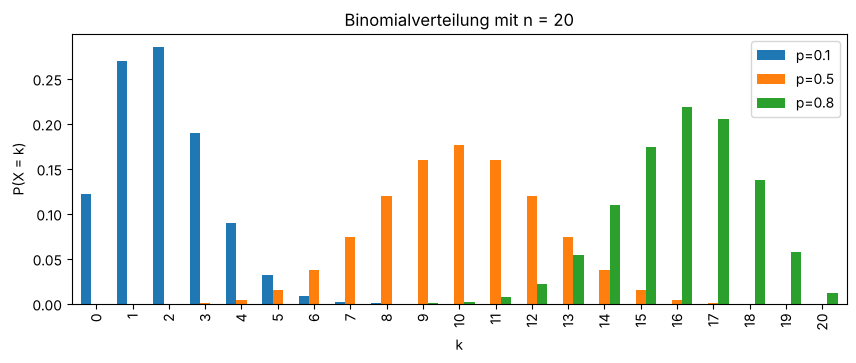

In [31]:
drei = pd.DataFrame({"k": range(21)})
for p_wert in [0.1, 0.5, 0.8]:
    drei[f"p={p_wert}"] = drei["k"].apply(lambda x: comb(20, x) * p_wert**x * (1 - p_wert)**(20 - x))
t = drei.set_index("k")

print("häufigster Wert je Spalte:", t.idxmax().tolist())
print("Erwartungswert je Spalte: ", t.mul(t.index, axis=0).sum().round(2).tolist())

t.plot.bar(figsize=(10, 3.5), width=0.85)
plt.ylabel("P(X = k)")
plt.title("Binomialverteilung mit n = 20")
plt.show()

- `idxmax()` auf einem DataFrame liefert für **jede Spalte** den Index mit dem größten Wert.
- `t.mul(t.index, axis=0)` multipliziert jede Zeile mit ihrem k, wie `div(..., axis=0)` aus Notebook 9. Die Spaltensumme ist der Erwartungswert n · p.
- Bei p = 0,1 ist die Verteilung rechtsschief, bei 0,5 symmetrisch, bei 0,8 linksschief.

### Übung 5

Übung 12 vom Vormittag: 10 Server, jeder fällt unabhängig mit 10 % aus.

- **a)** Erstelle die Tabelle P(X = k) für k = 0 bis 10 mit `apply`, dazu die kumulierte Spalte.
- **b)** Lies ab: P(kein Ausfall), P(genau einer), P(mindestens zwei).
- **c)** Herr Bauchgefühl: „10 · 10 % = 100 %, einer fällt sicher aus." Was hat er berechnet, und wie groß ist P(mindestens einer)?
- **d)** Prüfe mit `rng.binomial` (10 000 Tage, `rng = np.random.default_rng(10)`).

In [32]:
# a)


In [33]:
# b)


In [34]:
# c)


In [35]:
# d)


---
# Block F – `apply` zeilenweise und weitere Übungen

- **Abschnitt 13 und 14:** `apply` mit `axis=1`, die diskrete Gleichverteilung
- **Übung 6:** Fiete wird erwischt (zu Abschnitt 13 und Block E)
- **Übung 7:** Multiple-Choice raten (zu Block E)
- **Übung 8:** Würfelspiel: fair oder nicht? (zu Block B und C)
- **Übung 9:** Welcher Grundfall? (zu Block A)
- **Übung 10:** Münzwurf-Pfade (zu Block A)
- **Übung 11:** Gleich verteilt (zu Abschnitt 14)

## 13 – `apply` mit `axis=1`

Auf einem DataFrame mit `axis=1` bekommt die Funktion **eine ganze Zeile**. Auf die Werte greifst du mit dem Spaltennamen zu, zum Beispiel `zeile["w1"]`.

Beispiel: dreimal würfeln, 10 000-mal.

In [36]:
rng = np.random.default_rng(12)
wuerfe = pd.DataFrame(rng.integers(1, 7, size=(10_000, 3)), columns=["w1", "w2", "w3"])

# apply mit axis=1: jede Zeile als Text beschreiben
wuerfe["beschreibung"] = wuerfe.apply(lambda zeile: f"{zeile['w1']}-{zeile['w2']}-{zeile['w3']}", axis=1)
wuerfe.head()

,w1,w2,w3,beschreibung
0,4,2,6,4-2-6
1,6,1,2,6-1-2
2,2,2,4,2-2-4
3,3,3,2,3-3-2
4,6,5,4,6-5-4


Viele Aufgaben gehen auch **ohne** `apply`, das nennt man **vektorisiert**. Das ist deutlich schneller, weil Pandas die ganze Spalte auf einmal rechnet:

In [37]:
import time

start = time.perf_counter()
mit_apply = wuerfe.apply(lambda zeile: (zeile[["w1", "w2", "w3"]] == 6).sum(), axis=1)
zeit_apply = time.perf_counter() - start

start = time.perf_counter()
vektorisiert = (wuerfe[["w1", "w2", "w3"]] == 6).sum(axis=1)
zeit_vektor = time.perf_counter() - start

print("gleiches Ergebnis:", (mit_apply == vektorisiert).all())
print(f"apply:        {zeit_apply:.3f} s")
print(f"vektorisiert: {zeit_vektor:.4f} s")

gleiches Ergebnis: True
apply:        2.754 s
vektorisiert: 0.0017 s


> **Faustregel:** Erst überlegen, ob es mit `==`, `+`, `sum(axis=1)` und Co. geht. `apply(axis=1)` nur, wenn die Rechnung pro Zeile wirklich kompliziert ist.

## 14 – Die diskrete Gleichverteilung

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Gleichverteilt heißt: Ich zähle jede Augenzahl gleich oft, wenn ich lange genug würfle."

In [38]:
print(wuerfe["w1"].value_counts(normalize=True).sort_index().round(3))
print("Mittelwert:", round(wuerfe["w1"].mean(), 2), "| Erwartungswert: 3.5")

w1
1    0.165
2    0.170
3    0.165
4    0.167
5    0.165
6    0.169
Name: proportion, dtype: float64
Mittelwert: 3.51 | Erwartungswert: 3.5


**Lückenlos:** Die Lasttest-IDs aus dem Skript laufen von 1001 bis 1500. Das sind n = 1500 − 1001 + 1 = 500 Werte, jeder mit P = 0,002, und E = (1001 + 1500) / 2 = 1250,5.

> **Stolperstein:** `rng.integers(a, b)` liefert Zahlen von a bis **unter** b. Für „bis 1500" brauchst du `rng.integers(1001, 1501)`. Das ist der klassische Off-by-one-Fehler und genau das „+ 1" aus n = b − a + 1.

In [39]:
rng = np.random.default_rng(14)
ids = pd.Series(rng.integers(1001, 1501, size=100_000))
print("kleinste:", ids.min(), "| größte:", ids.max(), "| verschiedene:", ids.nunique())
print("Mittelwert:", round(ids.mean(), 1), "| Formel: 1250.5")

kleinste: 1001 | größte: 1500 | verschiedene: 500
Mittelwert: 1250.6 | Formel: 1250.5


**Mit Lücken:** Nimmt X die Werte 2, 5, 7, 11 an, ist E(X) einfach der Mittelwert aller Werte. Die Abkürzung (a + b) / 2 gilt nur ohne Lücken.

In [40]:
werte = pd.Series([2, 5, 7, 11])
print("Mittelwert aller Werte:", werte.mean())
print("(a + b) / 2:           ", (werte.min() + werte.max()) / 2, "  passt nicht")
print("simuliert:             ", round(werte.sample(n=100_000, replace=True, random_state=1).mean(), 2))

Mittelwert aller Werte: 6.25
(a + b) / 2:            6.5   passt nicht
simuliert:              6.24


> **Im Job:** Ein Load Balancer, der **zufällig** verteilt, schickt jede Anfrage mit P = 1/n an jeden Server. Round-Robin verteilt dagegen der Reihe nach, das ist kein Zufall, sondern eine feste Regel.

### Übung 6 – Fiete wird erwischt (zu Abschnitt 13 und Block E)

<img src="png%20Dateien/fiete_fuchs.png" alt="Fiete Fuchs" width="110">

Übung 14 vom Vormittag. Fietes neues Spiel: Einsatz 2 €. Du würfelst dreimal. Kommt mindestens zweimal eine Sechs, bekommst du 20 €. Arbeite mit `wuerfe` aus Abschnitt 13.

- **a)** Lege eine Spalte `sechsen` an (vektorisiert). Welche Verteilung hat X = Anzahl der Sechsen? Nenne n und p.
- **b)** Lege mit `apply` eine Spalte `auszahlung` an: 20, wenn mindestens zwei Sechsen, sonst 0. Wie groß ist P(X ≥ 2) in der Simulation? Vergleiche mit 16/216.
- **c)** Berechne den erwarteten Gewinn pro Spiel, simuliert und mit der Formel. Wer profitiert?
- **d)** Ab welchem Gewinnbetrag wäre das Spiel fair?

In [41]:
# a)


In [42]:
# b)


In [43]:
# c)


In [44]:
# d)


### Übung 7 – Multiple-Choice raten (zu Block E)

Übung 13 vom Vormittag: Ein Test hat 10 Fragen mit je 4 Antworten, genau eine ist richtig. Jemand rät bei jeder Frage.

- **a)** Warum ist X = Anzahl richtiger Antworten binomialverteilt? Nenne n und p (als Kommentar).
- **b)** Erstelle die Tabelle P(X = k) mit `apply` und berechne E(X) mit `(k * P).sum()`.
- **c)** Wie wahrscheinlich ist keine richtige Antwort, wie wahrscheinlich genau 5?
- **d)** Zusatz: Bestanden ist ab 5 richtigen. Wie wahrscheinlich besteht man durch reines Raten?

In [45]:
# a)


In [46]:
# b)


In [47]:
# c)


In [48]:
# d)


### Übung 8 – Würfelspiel: fair oder nicht? (zu Block B und C)

Übung 10 vom Vormittag: Einsatz 1 €. Bei einer 6 bekommst du 5 €, bei einer 5 bekommst du deinen Euro zurück, sonst nichts.

- **a)** Simuliere 10 000 Würfe mit `rng = np.random.default_rng(9)` und übersetze sie mit `map({6: 5, 5: 1})` in die Auszahlung. Was passiert mit den Augenzahlen 1 bis 4? Repariere es.
- **b)** Wie hoch sind die erwartete Auszahlung und der erwartete Gewinn? Ist das Spiel fair?
- **c)** Fiete ändert die Regel: Bei einer 6 gibt es nur noch 4 €. Wie hoch ist jetzt der erwartete Gewinn?
- **d)** Wie hoch ist der Mittelwert der Augenzahl? Welche Verteilung hat die Augenzahl?

In [49]:
# a)


In [50]:
# b)


In [51]:
# c)


In [52]:
# d)


### Übung 9 – Welcher Grundfall? (zu Block A)

Übungen 2 und 3 vom Vormittag. Prüfe deine Lösungen mit `itertools` und `len`.

- **a)** Fahrradschloss mit 3 Rädchen (0–9), Platz 1 bis 3 beim Hackathon mit 12 Teams, 2 von 8 Personen halten zusammen eine Präsentation, Reihenfolge von 5 Vorträgen.
- **b)** 10 Fachbücher: alle ins Regal, 3 in ein kleines Fach (Reihenfolge zählt), 3 mit in den Urlaub (Reihenfolge egal). Nutze für alle 10 Bücher `factorial`.

In [53]:
# a)


In [54]:
# b)


### Übung 10 – Münzwurf-Pfade (zu Block A)

Übung 6 vom Vormittag: Du wirfst eine Münze 5-mal.

- **a)** Berechne (5 über 2) mit `factorial` Schritt für Schritt und prüfe mit `comb`.
- **b)** Erzeuge alle Pfade mit `product("KZ", repeat=5)` und gib die Pfade mit genau 2-mal Kopf als Text aus.
- **c)** Wie wahrscheinlich ist genau 2-mal Kopf? Jeder Pfad hat die Wahrscheinlichkeit 0,5⁵.

In [55]:
# a)


In [56]:
# b)


In [57]:
# c)


### Übung 11 – Gleich verteilt (zu Abschnitt 14)

Übung 11 vom Vormittag. Alle Werte sind jeweils gleich wahrscheinlich.

- **a)** Ein Zufallsgenerator liefert eine ganze Zahl von 0 bis 99. Bestimme n, P(X = 42) und E(X). Prüfe mit 100 000 Zahlen aus `rng.integers` (`rng = np.random.default_rng(11)`). Achte auf die obere Grenze.
- **b)** X nimmt die Werte 1, 2, 4 und 8 an. Berechne E(X). Warum funktioniert (a + b) / 2 hier nicht?
- **c)** Ein Load Balancer verteilt Anfragen zufällig auf 4 Server. Simuliere 10 000 Anfragen. Wie oft landet eine Anfrage auf Server 3? Wäre das bei Round-Robin auch Zufall?

In [58]:
# a)


In [59]:
# b)


In [60]:
# c)


---
## 15 – Zusammenfassung

| Aufgabe | Befehl |
|---|---|
| alle Möglichkeiten | `pd.DataFrame(list(product(...)))`, `permutations`, `combinations` |
| Anzahl ohne Auflisten | `comb(n, k)`, `factorial(n)` |
| große Zahlen | `astype(float)` vor dem Potenzieren (`int64` läuft still über) |
| jeden Wert übersetzen | `series.map(dict)`, `series.map(funktion)`, `series.map(lambda x: ...)` |
| einzelne Werte ersetzen | `series.replace(dict)` (Unbekanntes bleibt stehen) |
| Erwartungswert | `(x * p).sum()`, `np.average(x, weights=p)` |
| Verteilungsfunktion | `p.cumsum()`; Kommazahlen vor dem Vergleich runden |
| kleine Verteilung | `pd.Series({wert: wahrscheinlichkeit, ...})` |
| Funktion auf jeden Wert | `series.apply(funktion)` |
| Funktion auf jede Zeile | `df.apply(funktion, axis=1)`, Zugriff mit `zeile["spalte"]` |
| Binomial simulieren | `rng.binomial(n=..., p=..., size=...)` |
| Zeile mal Index | `t.mul(t.index, axis=0)` |
| häufigster Wert je Spalte | `t.idxmax()` |
| ganze Zufallszahlen a bis b | `rng.integers(a, b + 1)` (obere Grenze exklusiv) |
| Textspalten zusammenkleben | `df[spalten].apply("".join, axis=1)` |
| Formel und Simulation vergleichen | `pd.DataFrame({...}).fillna(0)` |

**Merke:** `map` übersetzt, `replace` korrigiert, `apply` rechnet. Und wenn es vektorisiert geht, ist das schneller.

---
*Material erstellt von Julia Brutskaya | FIDP Daten- und Prozessanalyse*